In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Datasets/delivery_operations_students.csv')
df.head()

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp
0,DLV-0001,2.2,14,22,206
1,DLV-0002,2.1,17,12,190
2,DLV-0003,2.2,12,8,119
3,DLV-0004,2.0,22,11,113
4,DLV-0005,9.8,50,22,292


In [ ]:
# Define X
X = df.drop(columns=['order_id'])
# Scale X
scaler = StandardScaler()
X = scaler.fit_transform(X)

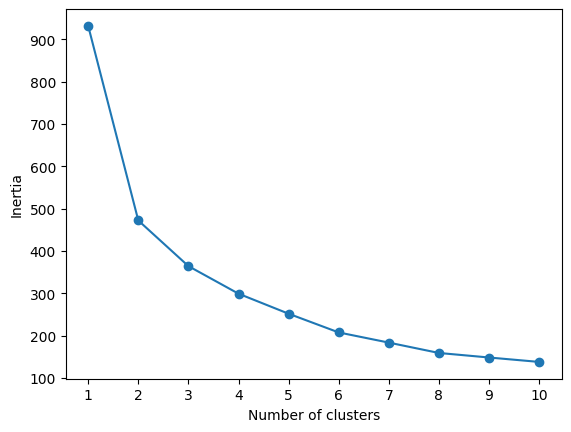

In [ ]:
# Elbow and Inertia for kmeans
inertias = []
k_values = range(1, 11)
for k in k_values:
  kmeans = KMeans(
      n_clusters=k,
      random_state=42,
      max_iter=100,
      n_init=10
  )
  kmeans.fit(X)
  inertias.append(kmeans.inertia_)

plt.plot(k_values, inertias, '-o')
plt.xticks(k_values)
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

In [ ]:
# Kmeans
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    max_iter=100,
    n_init=10)
kmeans.fit(X)

KMeans(max_iter=100, n_clusters=3, n_init=10, random_state=42)

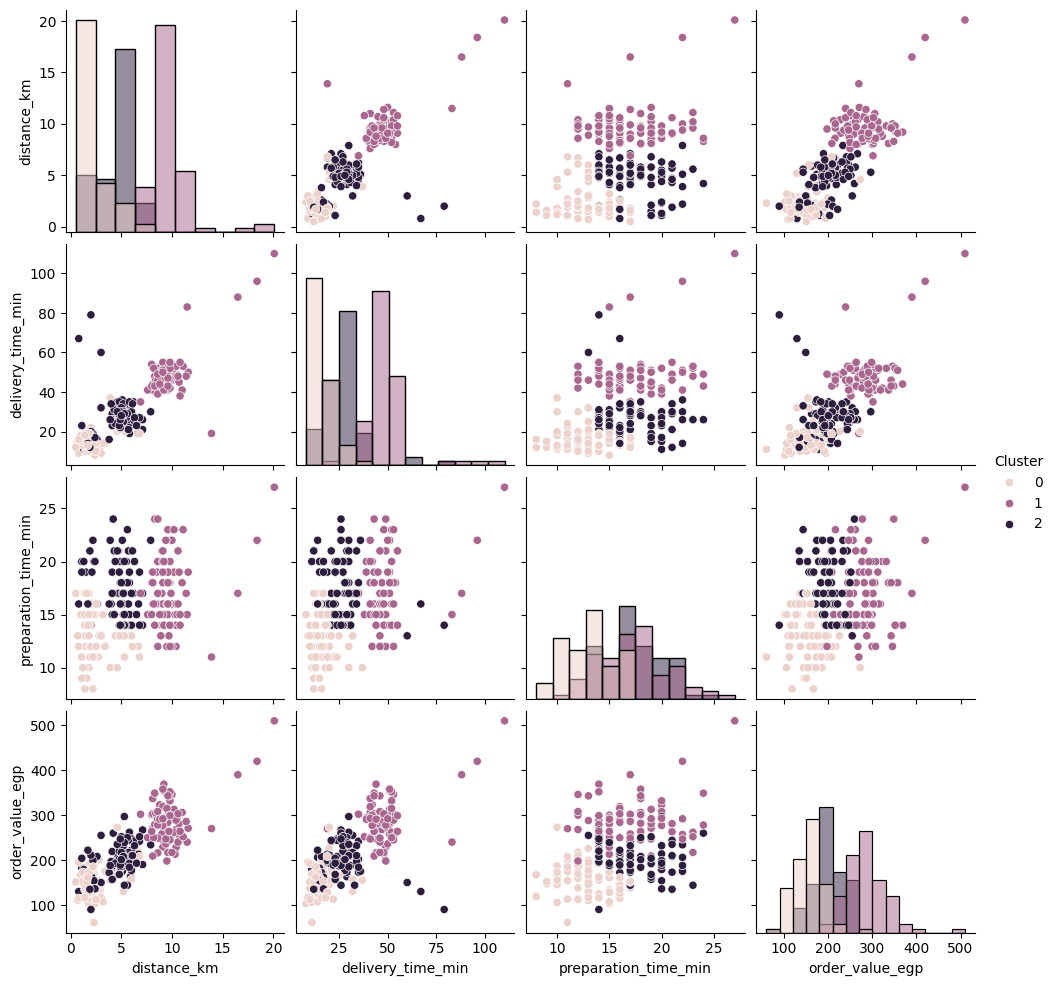

In [ ]:
features = [
    'distance_km',
    'delivery_time_min',
    'preparation_time_min',
    'order_value_egp'
]
plot_df = df[features].copy()
plot_df['Cluster'] = kmeans.labels_

sns.pairplot(
    plot_df,
    vars=features,
    hue='Cluster',
    diag_kind='hist'
)


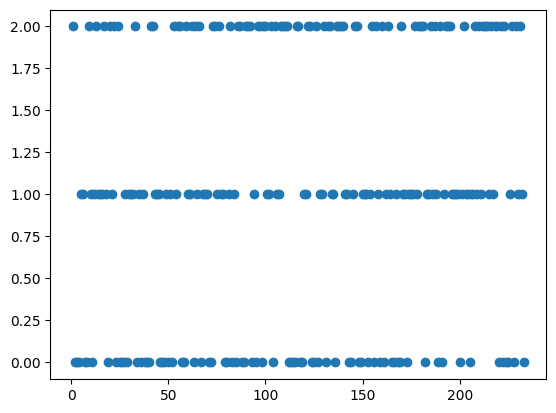

In [ ]:
plt.plot(range(1, df.shape[0] + 1), kmeans.labels_, 'o')
plt.show()

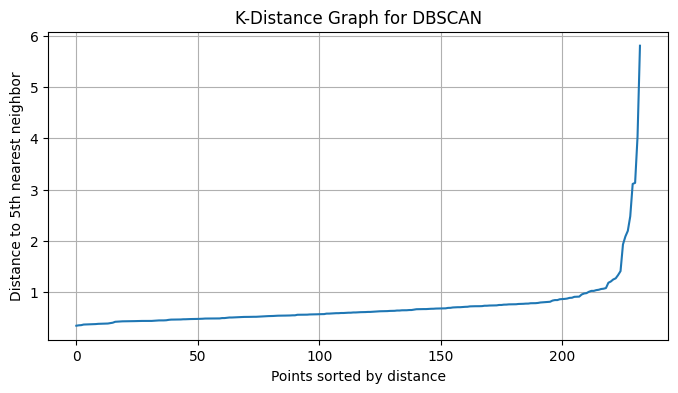

In [ ]:
# DBSCAN
import numpy as np
import matplotlib.pyplot as plt

min_samples = 7

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X)

distances, _ = neighbors.kneighbors(X)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to 5th nearest neighbor")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)

plt.show()

DBSCAN()

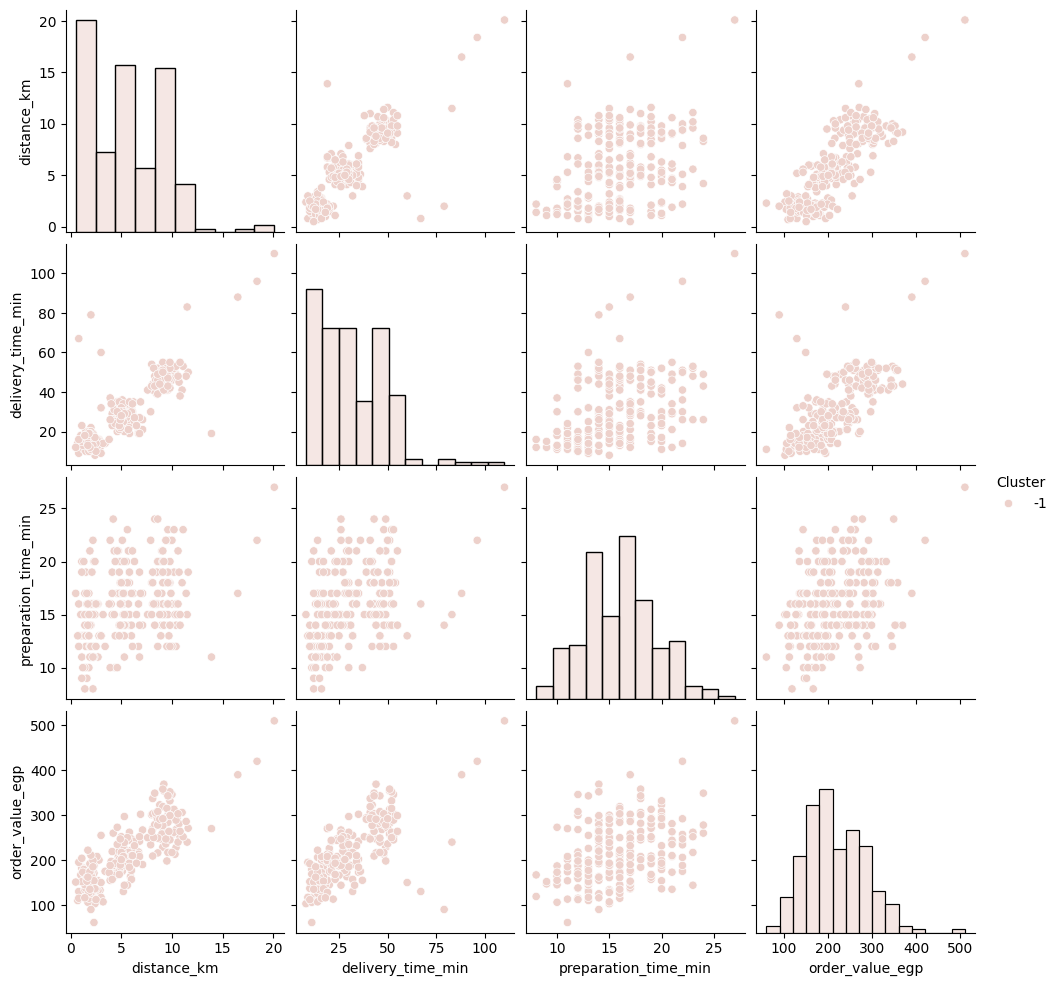

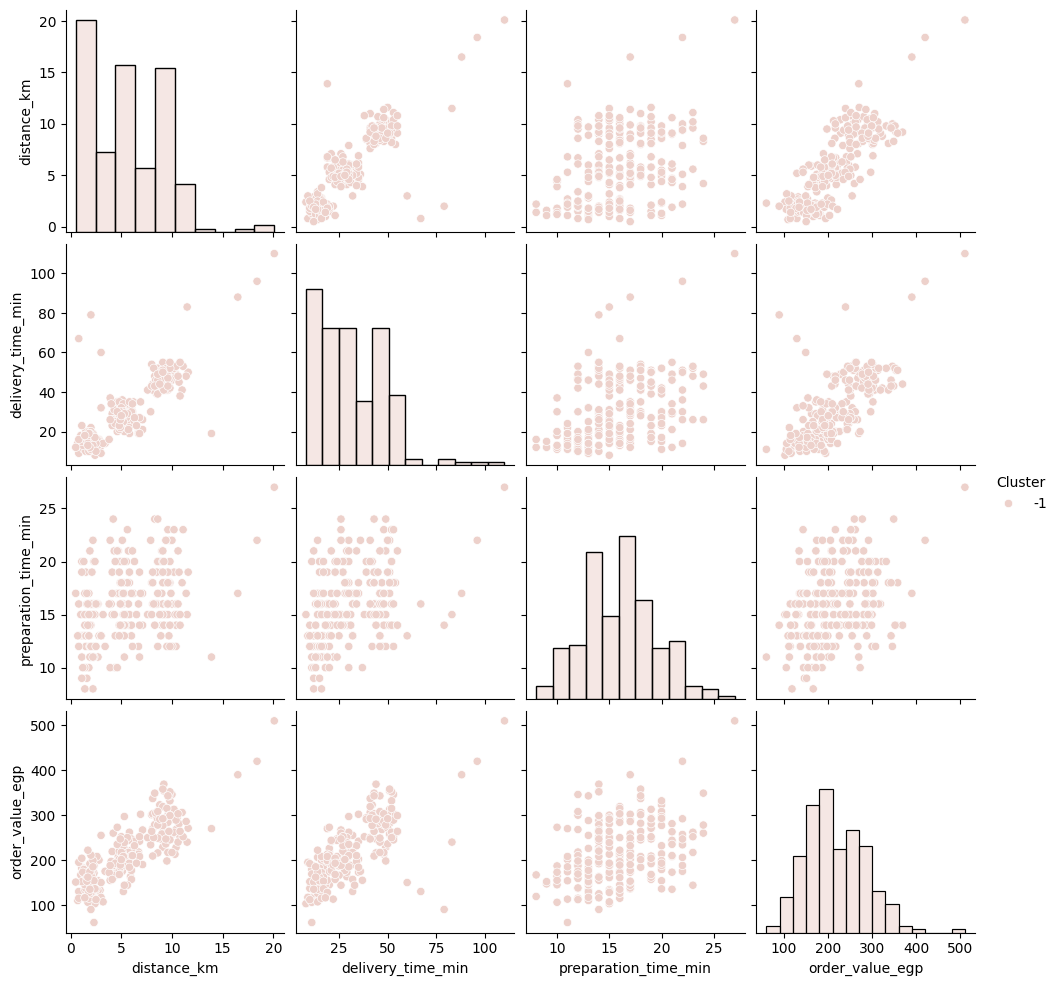

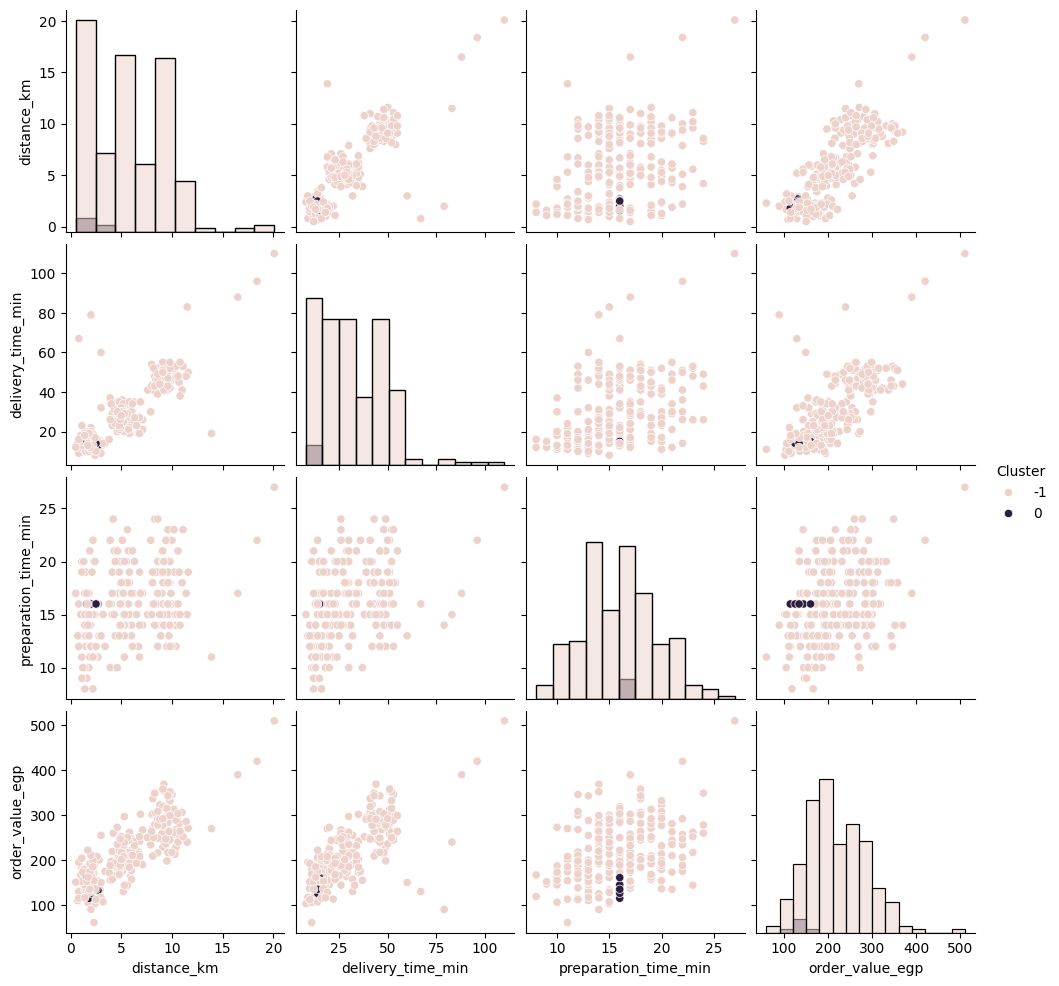

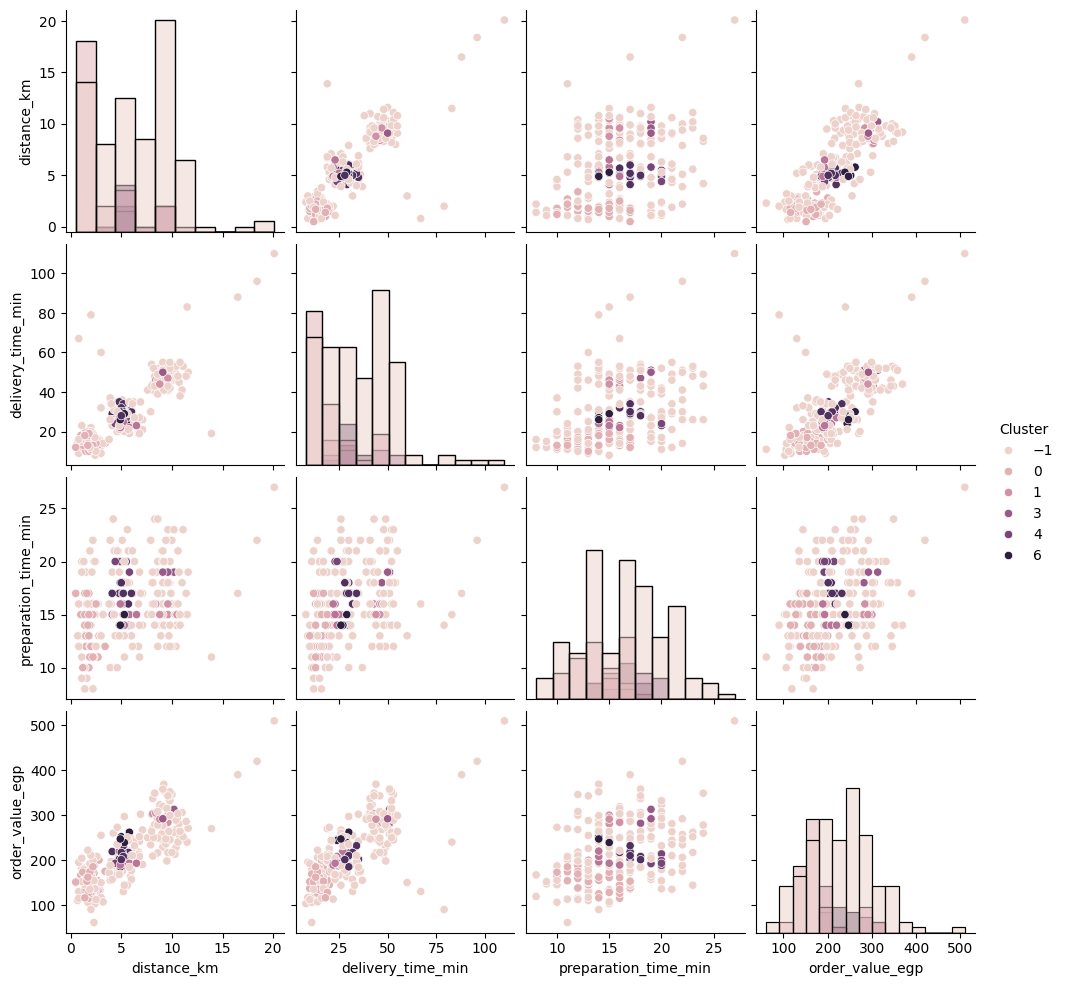

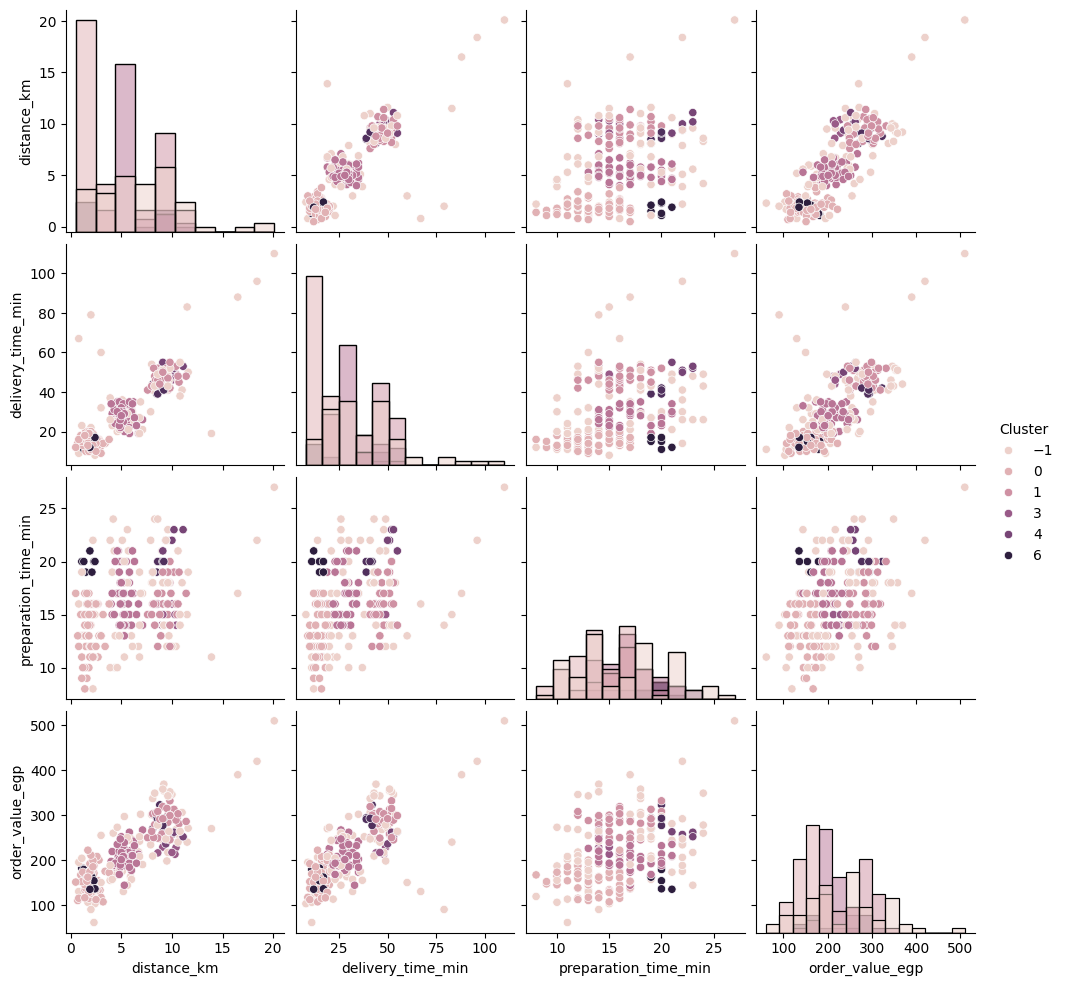

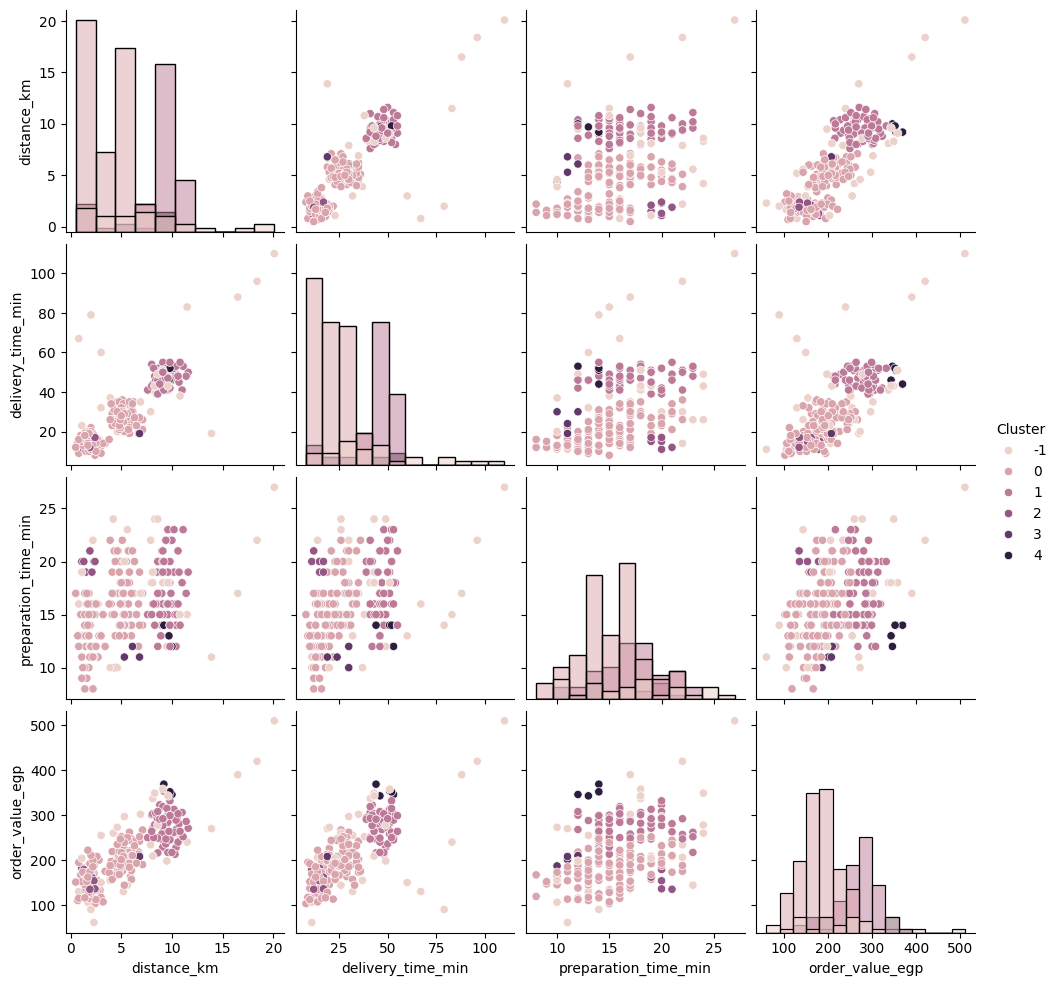

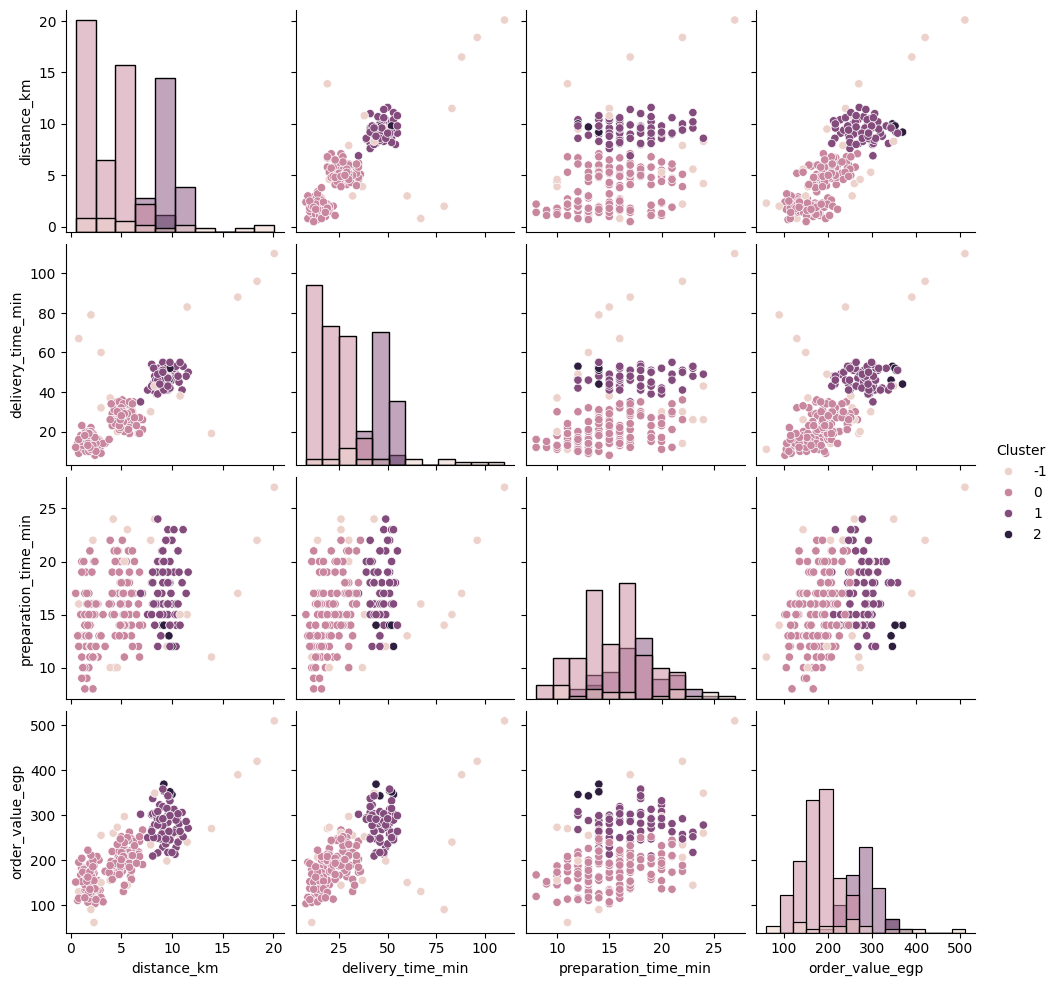

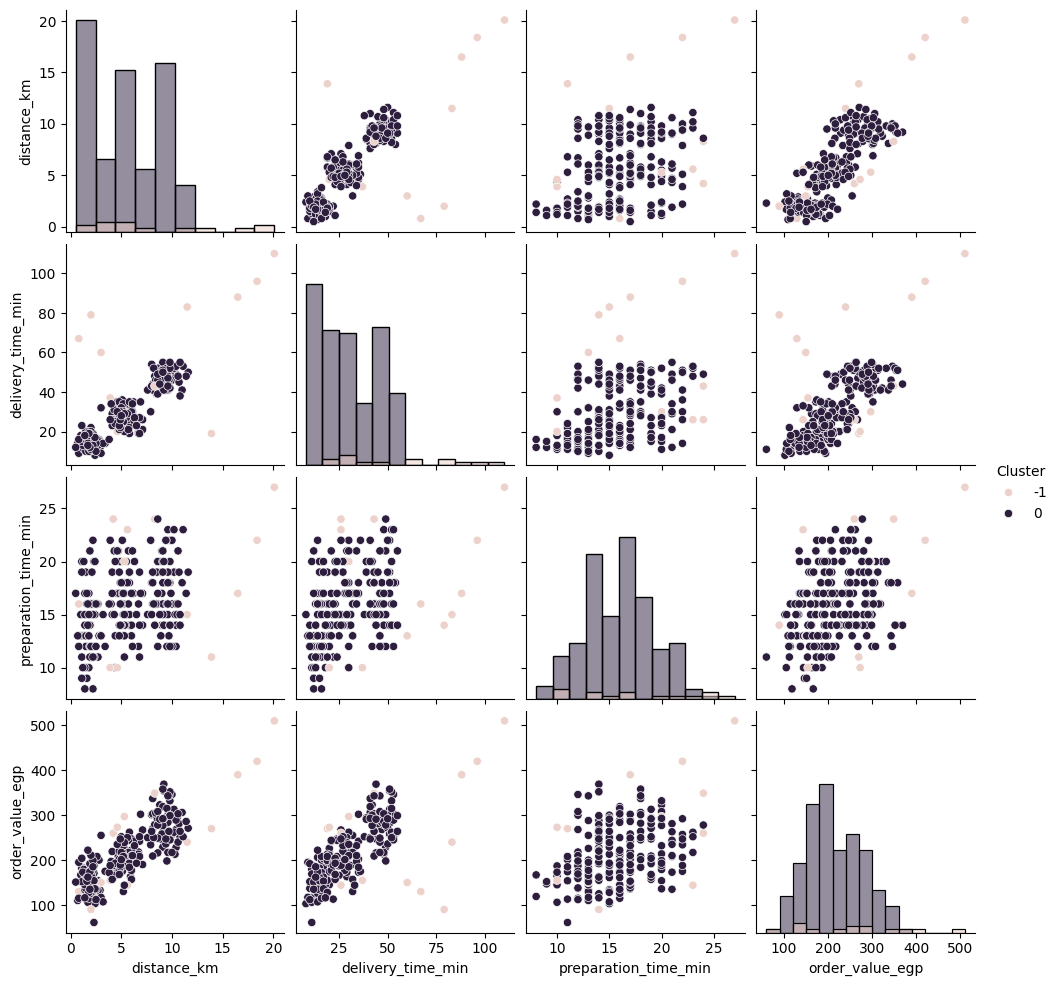

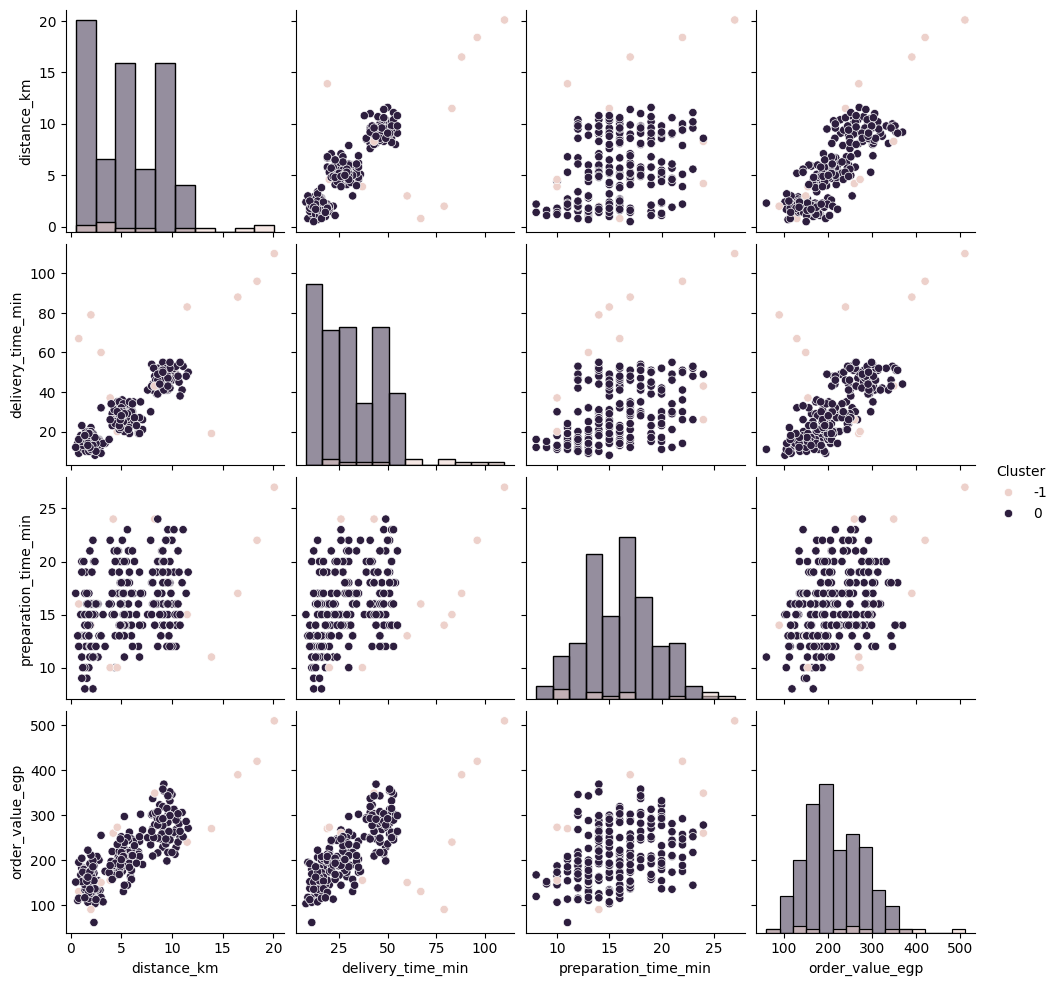

In [ ]:
for eps in range(1, 10):
  dbscan = DBSCAN(eps = eps * 0.1, min_samples = 5 )
  dbscan.fit(X)
  features = [
      'distance_km',
      'delivery_time_min',
      'preparation_time_min',
      'order_value_egp'
  ]
  plot_df = df[features].copy()
  plot_df['Cluster'] = dbscan.labels_

  sns.pairplot(
      plot_df,
      vars=features,
      hue='Cluster',
      diag_kind='hist'
  )


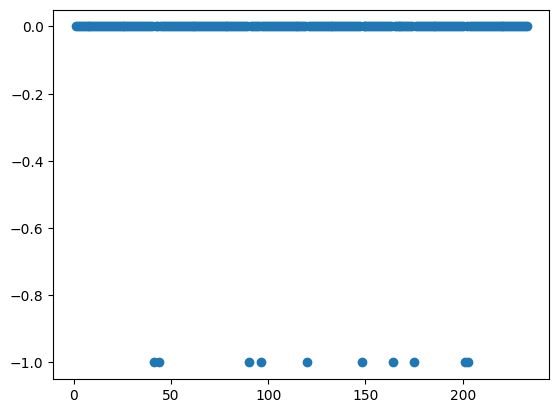

In [ ]:
plt.plot(range(1, df.shape[0] + 1), dbscan.labels_, 'o')
plt.show()